# Segmentation des clients e-commerce

Pipeline Big Data avec PySpark : exploration, nettoyage, analyse RFM, comparaison de deux algorithmes de clustering et sauvegarde de la segmentation retenue.

## 1. Initialisation et chargement

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("EcommerceCustomerSegmentation")
    .getOrCreate()
)

In [3]:
path = "/home/jovyan/work/data/raw/OnlineRetail.csv"

df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("encoding", "UTF-8")
    .csv(path)
)

print("Number of rows:", df.count())
print("number of columns:", len(df.columns))

Number of rows: 541909
number of columns: 8


In [4]:
df.show(10, truncate=False)

+---------+---------+-----------------------------------+--------+--------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate   |UnitPrice|CustomerID|Country       |
+---------+---------+-----------------------------------+--------+--------------+---------+----------+--------------+
|536365   |85123A   |WHITE HANGING HEART T-LIGHT HOLDER |6       |12/1/2010 8:26|2.55     |17850     |United Kingdom|
|536365   |71053    |WHITE METAL LANTERN                |6       |12/1/2010 8:26|3.39     |17850     |United Kingdom|
|536365   |84406B   |CREAM CUPID HEARTS COAT HANGER     |8       |12/1/2010 8:26|2.75     |17850     |United Kingdom|
|536365   |84029G   |KNITTED UNION FLAG HOT WATER BOTTLE|6       |12/1/2010 8:26|3.39     |17850     |United Kingdom|
|536365   |84029E   |RED WOOLLY HOTTIE WHITE HEART.     |6       |12/1/2010 8:26|3.39     |17850     |United Kingdom|
|536365   |22752    |SET 7 BABUSHKA NESTING BOXES       

In [5]:
df.printSchema()

root
 |-- InvoiceNo: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: string (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- CustomerID: integer (nullable = true)
 |-- Country: string (nullable = true)



## 2. Exploration et qualité des données

In [6]:
missing = df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in df.columns
])

missing.show()

+---------+---------+-----------+--------+-----------+---------+----------+-------+
|InvoiceNo|StockCode|Description|Quantity|InvoiceDate|UnitPrice|CustomerID|Country|
+---------+---------+-----------+--------+-----------+---------+----------+-------+
|        0|        0|       1454|       0|          0|        0|    135080|      0|
+---------+---------+-----------+--------+-----------+---------+----------+-------+



In [7]:
print("Total rows:", df.count())
print("Distinct rows:", df.distinct().count())

Total rows: 541909
Distinct rows: 536641


In [8]:
df.filter(
    F.col("InvoiceNo").startswith("C")
).select("InvoiceNo", "Quantity").show(20)

+---------+--------+
|InvoiceNo|Quantity|
+---------+--------+
|  C536379|      -1|
|  C536383|      -1|
|  C536391|     -12|
|  C536391|     -24|
|  C536391|     -24|
|  C536391|     -24|
|  C536391|     -12|
|  C536391|     -12|
|  C536391|     -24|
|  C536506|      -6|
|  C536543|      -1|
|  C536543|      -2|
|  C536548|      -4|
|  C536548|      -5|
|  C536548|      -1|
|  C536548|      -7|
|  C536548|      -1|
|  C536548|      -2|
|  C536548|      -1|
|  C536548|      -2|
+---------+--------+
only showing top 20 rows


In [9]:
print("Unique customers:", df.select("CustomerID").distinct().count())
print("Unique products:", df.select("StockCode").distinct().count())
print("Unique countries:", df.select("Country").distinct().count())

Unique customers: 4373
Unique products: 4070
Unique countries: 38


In [10]:
df.groupBy("Country") \
  .count() \
  .orderBy(F.desc("count")) \
  .show(15)

+---------------+------+
|        Country| count|
+---------------+------+
| United Kingdom|495478|
|        Germany|  9495|
|         France|  8557|
|           EIRE|  8196|
|          Spain|  2533|
|    Netherlands|  2371|
|        Belgium|  2069|
|    Switzerland|  2002|
|       Portugal|  1519|
|      Australia|  1259|
|         Norway|  1086|
|          Italy|   803|
|Channel Islands|   758|
|        Finland|   695|
|         Cyprus|   622|
+---------------+------+
only showing top 15 rows


In [11]:
print("Data quality checks")

duplicates = df.count() - df.dropDuplicates().count()
cancellations = df.filter(
    F.col("InvoiceNo").startswith("C")
).count()

negative_quantity = df.filter(
    F.col("Quantity") < 0
).count()

non_positive_price = df.filter(
    F.col("UnitPrice") <= 0
).count()

print(f"Doublons: {duplicates:,}")
print(f"Factures d'annulation: {cancellations:,}")
print(f"Quantités négatives: {negative_quantity:,}")
print(f"Prix non positifs: {non_positive_price:,}")

Data quality checks
Doublons: 5,268
Factures d'annulation: 9,288
Quantités négatives: 10,624
Prix non positifs: 2,517


## 3. Analyse temporelle

In [12]:
print("Transaction date analysis")

df_dates = df.withColumn(
    "InvoiceDate_ts",
    F.to_timestamp(
        F.col("InvoiceDate"),
        "M/d/yyyy H:mm"
    )
)

print("\n ------ Verification de la conversion ------" )

df_dates.select(
    "InvoiceDate",
    "InvoiceDate_ts"
).show(10, truncate=False)

print("\n------ Dates invalides ------")

invalid_dates = df_dates.filter(
    F.col("InvoiceDate_ts").isNull()
).count()

print(f"Dates invalides : {invalid_dates:,}")

print("\n------ Periode des transactions ------")

df_dates.select(
    F.min("InvoiceDate_ts").alias("date_min"),
    F.max("InvoiceDate_ts").alias("date_max")
).show(truncate=False)
df_dates.withColumn(
    "year",
    F.year("InvoiceDate_ts")
).groupBy(
    "year"
).count().orderBy(
    "year"
).show()

print("\n------ Transactions par mois ------")

df_dates.withColumn(
    "year_month",
    F.date_format(
        "InvoiceDate_ts",
        "yyyy-MM"
    )
).groupBy(
    "year_month"
).count().orderBy(
    "year_month"
).show(30)

print("\n------ Transactions par jour de la semaine ------")

df_dates.withColumn(
    "day_of_week",
    F.date_format(
        "InvoiceDate_ts",
        "EEEE"
    )
).groupBy(
    "day_of_week"
).count().orderBy(
    F.desc("count")
).show()

Transaction date analysis

 ------ Verification de la conversion ------
+--------------+-------------------+
|InvoiceDate   |InvoiceDate_ts     |
+--------------+-------------------+
|12/1/2010 8:26|2010-12-01 08:26:00|
|12/1/2010 8:26|2010-12-01 08:26:00|
|12/1/2010 8:26|2010-12-01 08:26:00|
|12/1/2010 8:26|2010-12-01 08:26:00|
|12/1/2010 8:26|2010-12-01 08:26:00|
|12/1/2010 8:26|2010-12-01 08:26:00|
|12/1/2010 8:26|2010-12-01 08:26:00|
|12/1/2010 8:28|2010-12-01 08:28:00|
|12/1/2010 8:28|2010-12-01 08:28:00|
|12/1/2010 8:34|2010-12-01 08:34:00|
+--------------+-------------------+
only showing top 10 rows

------ Dates invalides ------
Dates invalides : 0

------ Periode des transactions ------
+-------------------+-------------------+
|date_min           |date_max           |
+-------------------+-------------------+
|2010-12-01 08:26:00|2011-12-09 12:50:00|
+-------------------+-------------------+

+----+------+
|year| count|
+----+------+
|2010| 42481|
|2011|499428|
+----+------+

## 4. Nettoyage

In [13]:
print("Cleaning dataset")

df_clean = (
    df
    .withColumn(
        "InvoiceDate",
        F.to_timestamp(
            "InvoiceDate",
            "M/d/yyyy H:mm"
        )
    )
)

initial_count = df_clean.count()

print(f"\nNombre initial de lignes : {initial_count:,}")

before_duplicates = df_clean.count()

df_clean = df_clean.dropDuplicates()

after_duplicates = df_clean.count()

duplicates_removed = (
    before_duplicates - after_duplicates
)

print("\n ------ Doublons ------")

print(f"Avant       : {before_duplicates:,}")
print(f"Après       : {after_duplicates:,}")
print(f"Supprimés   : {duplicates_removed:,}")

before_customer = df_clean.count()

df_clean = df_clean.filter(
    F.col("CustomerID").isNotNull()
)

after_customer = df_clean.count()

customer_removed = (
    before_customer - after_customer
)

print("\n ------CustomerID manquants------")

print(f"Avant       : {before_customer:,}")
print(f"Après       : {after_customer:,}")
print(f"Supprimés   : {customer_removed:,}")

before_cancel = df_clean.count()

df_clean = df_clean.filter(
    ~F.col("InvoiceNo")
    .cast("string")
    .startswith("C")
)

after_cancel = df_clean.count()

cancel_removed = (
    before_cancel - after_cancel
)

print("\n ------Factures annulées ------")

print(f"Avant       : {before_cancel:,}")
print(f"Après       : {after_cancel:,}")
print(f"Supprimées  : {cancel_removed:,}")

before_quantity = df_clean.count()

df_clean = df_clean.filter(
    F.col("Quantity") > 0
)

after_quantity = df_clean.count()

quantity_removed = (
    before_quantity - after_quantity
)

print("\n ------ Quantités invalides ------")

print(f"Avant       : {before_quantity:,}")
print(f"Après       : {after_quantity:,}")
print(f"Supprimées  : {quantity_removed:,}")

before_price = df_clean.count()

df_clean = df_clean.filter(
    F.col("UnitPrice") > 0
)

after_price = df_clean.count()

price_removed = (
    before_price - after_price
)

print("\n ------ Prix invalides ------")

print(f"Avant       : {before_price:,}")
print(f"Après       : {after_price:,}")
print(f"Supprimés   : {price_removed:,}")

df_clean = df_clean.withColumn(
    "Revenue",
    F.col("Quantity") * F.col("UnitPrice")
)

final_count = df_clean.count()

print("Cleaning summary")

print(f"Lignes initiales : {initial_count:,}")
print(f"Lignes finales   : {final_count:,}")
print(
    f"Lignes supprimées: "
    f"{initial_count - final_count:,}"
)

print(
    f"Taux de conservation : "
    f"{final_count / initial_count * 100:.2f}%"
)

print(
    f"Taux de suppression : "
    f"{(initial_count - final_count) / initial_count * 100:.2f}%"
)

print("\n ------Vérification du dataset nettoyé ------")

df_clean.select(
    F.count("*").alias("lignes"),
    F.countDistinct("CustomerID").alias("clients"),
    F.countDistinct("InvoiceNo").alias("factures"),
    F.countDistinct("StockCode").alias("produits"),
    F.sum("Revenue").alias("revenu_total")
).show()

print("\n ------Apercu ------")

df_clean.show(10, truncate=False)

Cleaning dataset

Nombre initial de lignes : 541,909

 ------ Doublons ------
Avant       : 541,909
Après       : 536,641
Supprimés   : 5,268

 ------CustomerID manquants------
Avant       : 536,641
Après       : 401,604
Supprimés   : 135,037

 ------Factures annulées ------
Avant       : 401,604
Après       : 392,732
Supprimées  : 8,872

 ------ Quantités invalides ------
Avant       : 392,732
Après       : 392,732
Supprimées  : 0

 ------ Prix invalides ------
Avant       : 392,732
Après       : 392,692
Supprimés   : 40
Cleaning summary
Lignes initiales : 541,909
Lignes finales   : 392,692
Lignes supprimées: 149,217
Taux de conservation : 72.46%
Taux de suppression : 27.54%

 ------Vérification du dataset nettoyé ------
+------+-------+--------+--------+----------------+
|lignes|clients|factures|produits|    revenu_total|
+------+-------+--------+--------+----------------+
|392692|   4338|   18532|    3665|8887208.89400003|
+------+-------+--------+--------+----------------+


 -----

## 5. Construction du RFM et opérations RDD

In [14]:
print("RFM construction")
print(f"Transactions : {df_clean.count():,}")
print(
    f"Clients      : "
    f"{df_clean.select('CustomerID').distinct().count():,}"
)

print("\nDate de référence")
max_date = df_clean.select(
    F.max("InvoiceDate")
).collect()[0][0]

reference_date = max_date

print(f"Dernière transaction : {max_date}")
print(f"Date de référence    : {reference_date}")
rfm = (
    df_clean
    .groupBy("CustomerID")
    .agg(

        F.datediff(
            F.lit(reference_date),
            F.max("InvoiceDate")
        ).alias("Recency"),

        F.countDistinct(
            "InvoiceNo"
        ).alias("Frequency"),

        F.round(
            F.sum("Revenue"),
            2
        ).alias("Monetary")
    )
)

print("RFM created")
rfm.show(15, truncate=False)
rfm_count = rfm.count()

print(f"Clients dans RFM : {rfm_count:,}")
rfm.select(
    "Recency",
    "Frequency",
    "Monetary"
).describe().show()
quantiles = rfm.approxQuantile(
    ["Recency", "Frequency", "Monetary"],
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99],
    0.01
)

for column, values in zip(
    ["Recency", "Frequency", "Monetary"],
    quantiles
):
    print(f"\n{column}")

    for q, value in zip(
        ["1%", "5%", "25%", "50%", "75%", "90%", "95%", "99%"],
        values
    ):
        print(f"  {q:>3} : {value:.2f}")
rfm.orderBy(
    F.desc("Monetary")
).show(20, truncate=False)
rfm.orderBy(
    F.desc("Frequency")
).show(20, truncate=False)
rfm.orderBy(
    F.asc("Recency")
).show(20, truncate=False)
rfm_rdd = rfm.rdd.map(
    lambda row: (
        row["CustomerID"],
        row["Recency"],
        row["Frequency"],
        row["Monetary"]
    )
)

print(
    f"Nombre d'éléments dans le RDD : "
    f"{rfm_rdd.count():,}"
)

high_value_rdd = rfm_rdd.filter(
    lambda x: x[3] > 1000
)

high_value_count = high_value_rdd.count()

print(
    f"Clients avec Monetary > 1000 : "
    f"{high_value_count:,}"
)

print("\nExemple de résultats RDD :")

for customer in high_value_rdd.take(10):
    print(customer)
total_monetary_rdd = rfm_rdd.map(
    lambda x: x[3]
).sum()

print(
    f"Somme Monetary via RDD : "
    f"{total_monetary_rdd:,.2f}"
)

print("\n" + "=" * 70)

RFM construction
Transactions : 392,692
Clients      : 4,338

Date de référence
Dernière transaction : 2011-12-09 12:50:00
Date de référence    : 2011-12-09 12:50:00
RFM created
+----------+-------+---------+--------+
|CustomerID|Recency|Frequency|Monetary|
+----------+-------+---------+--------+
|17389     |0      |34       |31833.68|
|14450     |180    |3        |483.25  |
|15727     |16     |7        |5159.06 |
|15790     |10     |1        |218.75  |
|13285     |23     |4        |2709.12 |
|14570     |280    |2        |218.06  |
|16574     |71     |1        |451.44  |
|15619     |10     |1        |336.4   |
|13832     |19     |1        |52.2    |
|14465     |246    |3        |1038.44 |
|15967     |23     |2        |397.68  |
|14423     |218    |1        |265.2   |
|18161     |15     |5        |1618.69 |
|14536     |259    |1        |170.95  |
|12471     |2      |30       |19788.65|
+----------+-------+---------+--------+
only showing top 15 rows
Clients dans RFM : 4,338
+-------+---

## 6. Analyse des distributions RFM

In [15]:
print("RFM distribution analysis")
rfm.select(
    "Recency",
    "Frequency",
    "Monetary"
).summary(
    "count",
    "min",
    "1%",
    "5%",
    "10%",
    "25%",
    "50%",
    "75%",
    "90%",
    "95%",
    "99%",
    "max"
).show()
recency_distribution = (
    rfm
    .withColumn(
        "RecencyGroup",
        F.when(F.col("Recency") <= 7, "0-7 jours")
        .when(F.col("Recency") <= 30, "8-30 jours")
        .when(F.col("Recency") <= 90, "31-90 jours")
        .when(F.col("Recency") <= 180, "91-180 jours")
        .when(F.col("Recency") <= 365, "181-365 jours")
        .otherwise(">365 jours")
    )
    .groupBy("RecencyGroup")
    .count()
)

recency_distribution.show()
frequency_distribution = (
    rfm
    .withColumn(
        "FrequencyGroup",
        F.when(F.col("Frequency") == 1, "1 commande")
        .when(F.col("Frequency") <= 3, "2-3 commandes")
        .when(F.col("Frequency") <= 5, "4-5 commandes")
        .when(F.col("Frequency") <= 10, "6-10 commandes")
        .when(F.col("Frequency") <= 20, "11-20 commandes")
        .otherwise(">20 commandes")
    )
    .groupBy("FrequencyGroup")
    .count()
)

frequency_distribution.show()
monetary_distribution = (
    rfm
    .withColumn(
        "MonetaryGroup",
        F.when(F.col("Monetary") <= 100, "0-100")
        .when(F.col("Monetary") <= 500, "101-500")
        .when(F.col("Monetary") <= 1000, "501-1000")
        .when(F.col("Monetary") <= 5000, "1001-5000")
        .when(F.col("Monetary") <= 10000, "5001-10000")
        .otherwise(">10000")
    )
    .groupBy("MonetaryGroup")
    .count()
)

monetary_distribution.show()
print("\nTop 10 Monetary :")

rfm.orderBy(
    F.desc("Monetary")
).select(
    "CustomerID",
    "Recency",
    "Frequency",
    "Monetary"
).show(10)

print("\nTop 10 Frequency :")

rfm.orderBy(
    F.desc("Frequency")
).select(
    "CustomerID",
    "Recency",
    "Frequency",
    "Monetary"
).show(10)
rfm_transformed = (
    rfm
    .withColumn(
        "Recency_log",
        F.log1p("Recency")
    )
    .withColumn(
        "Frequency_log",
        F.log1p("Frequency")
    )
    .withColumn(
        "Monetary_log",
        F.log1p("Monetary")
    )
)
print("\nAvant transformation :")

rfm.select(
    "Recency",
    "Frequency",
    "Monetary"
).describe().show()

print("\nAprès transformation logarithmique :")

rfm_transformed.select(
    "Recency_log",
    "Frequency_log",
    "Monetary_log"
).describe().show()
log_quantiles = rfm_transformed.approxQuantile(
    [
        "Recency_log",
        "Frequency_log",
        "Monetary_log"
    ],
    [
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ],
    0.01
)

for column, values in zip(
    [
        "Recency_log",
        "Frequency_log",
        "Monetary_log"
    ],
    log_quantiles
):

    print(f"\n{column}")

    for q, value in zip(
        [
            "1%",
            "5%",
            "25%",
            "50%",
            "75%",
            "90%",
            "95%",
            "99%"
        ],
        values
    ):
        print(f"  {q:>3} : {value:.4f}")
print(
    "Recency ↔ Frequency :",
    rfm.stat.corr("Recency", "Frequency")
)

print(
    "Recency ↔ Monetary  :",
    rfm.stat.corr("Recency", "Monetary")
)

print(
    "Frequency ↔ Monetary :",
    rfm.stat.corr("Frequency", "Monetary")
)

print("\n" + "=" * 70)

RFM distribution analysis
+-------+-------+---------+---------+
|summary|Recency|Frequency| Monetary|
+-------+-------+---------+---------+
|  count|   4338|     4338|     4338|
|    min|      0|        1|     3.75|
|     1%|      1|        1|     52.2|
|     5%|      2|        1|   111.68|
|    10%|      5|        1|   155.17|
|    25%|     17|        1|   306.46|
|    50%|     50|        2|   668.56|
|    75%|    142|        5|  1660.88|
|    90%|    263|        9|  3641.24|
|    95%|    311|       13|  5836.86|
|    99%|    369|       30| 19788.65|
|    max|    373|      209|280206.02|
+-------+-------+---------+---------+

+-------------+-----+
| RecencyGroup|count|
+-------------+-----+
| 91-180 jours|  591|
|   8-30 jours| 1131|
|    0-7 jours|  536|
|   >365 jours|   64|
|  31-90 jours| 1222|
|181-365 jours|  794|
+-------------+-----+

+---------------+-----+
| FrequencyGroup|count|
+---------------+-----+
|  >20 commandes|   95|
| 6-10 commandes|  535|
|  2-3 commandes| 1343|


## 7. Préparation des variables et standardisation

In [16]:
from pyspark.ml.feature import VectorAssembler

features = [
    "Recency_log",
    "Frequency_log",
    "Monetary_log"
]

print("\nVariables utilisées :")
for feature in features:
    print(f"  ✓ {feature}")

assembler = VectorAssembler(
    inputCols=features,
    outputCol="features_raw"
)

rfm_vector = assembler.transform(rfm_transformed)

print("\nExemple de vecteurs :")

rfm_vector.select(
    "CustomerID",
    "Recency_log",
    "Frequency_log",
    "Monetary_log",
    "features_raw"
).show(10, truncate=False)


Variables utilisées :
  ✓ Recency_log
  ✓ Frequency_log
  ✓ Monetary_log

Exemple de vecteurs :
+----------+------------------+------------------+------------------+---------------------------------------------------------+
|CustomerID|Recency_log       |Frequency_log     |Monetary_log      |features_raw                                             |
+----------+------------------+------------------+------------------+---------------------------------------------------------+
|17389     |0.0               |3.5553480614894135|10.36831154057086 |[0.0,3.5553480614894135,10.36831154057086]               |
|14450     |5.198497031265826 |1.3862943611198906|6.182601302287106 |[5.198497031265826,1.3862943611198906,6.182601302287106] |
|15727     |2.833213344056216 |2.0794415416798357|8.548703486314981 |[2.833213344056216,2.0794415416798357,8.548703486314981] |
|15790     |2.3978952727983707|0.6931471805599453|5.392490536565286 |[2.3978952727983707,0.6931471805599453,5.392490536565286]|
|13285 

In [17]:
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(rfm_vector)

rfm_scaled = scaler_model.transform(rfm_vector)

print("\nExemple avant / après standardisation :")

rfm_scaled.select(
    "CustomerID",
    "features_raw",
    "features"
).show(10, truncate=False)


Exemple avant / après standardisation :
+----------+---------------------------------------------------------+--------------------------------------------------------------+
|CustomerID|features_raw                                             |features                                                      |
+----------+---------------------------------------------------------+--------------------------------------------------------------+
|17389     |[0.0,3.5553480614894135,10.36831154057086]               |[-2.7471805075492384,3.2348906898097853,3.003524616255651]    |
|14450     |[5.198497031265826,1.3862943611198906,6.182601302287106] |[1.0099896128136656,0.059598594975754815,-0.32259117957242484]|
|15727     |[2.833213344056216,2.0794415416798357,8.548703486314981] |[-0.6994993303014615,1.0743013488142301,1.557598656995262]    |
|15790     |[2.3978952727983707,0.6931471805599453,5.392490536565286]|[-1.0141218145208533,-0.9551041588627207,-0.9504415917401592] |
|13285     |[3.178053

In [18]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

k_values = list(range(2, 9))

print(f"\nValeurs de K testées : {k_values}")

evaluator = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="prediction",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)


Valeurs de K testées : [2, 3, 4, 5, 6, 7, 8]


In [19]:
results = []

for k in k_values:

    print(f"\n→ Entraînement K-Means avec K = {k}")

    kmeans = KMeans(
        k=k,
        seed=42,
        featuresCol="features",
        predictionCol="prediction",
        maxIter=100
    )

    model = kmeans.fit(rfm_scaled)

    predictions = model.transform(rfm_scaled)

    silhouette = evaluator.evaluate(predictions)

    cost = model.summary.trainingCost

    results.append(
        (
            k,
            silhouette,
            cost
        )
    )

    print(f"   Silhouette Score : {silhouette:.4f}")
    print(f"   Training Cost    : {cost:.2f}")

print("\n" + "=" * 70)
print("RÉSULTATS K-MEANS")

print(
    f"{'K':<8}"
    f"{'Silhouette':<20}"
    f"{'Training Cost':<20}"
)
for k, silhouette, cost in results:

    print(
        f"{k:<8}"
        f"{silhouette:<20.4f}"
        f"{cost:<20.2f}"
    )


→ Entraînement K-Means avec K = 2
   Silhouette Score : 0.6238
   Training Cost    : 6486.51

→ Entraînement K-Means avec K = 3
   Silhouette Score : 0.5013
   Training Cost    : 4878.00

→ Entraînement K-Means avec K = 4
   Silhouette Score : 0.4999
   Training Cost    : 3961.85

→ Entraînement K-Means avec K = 5
   Silhouette Score : 0.4772
   Training Cost    : 3330.25

→ Entraînement K-Means avec K = 6
   Silhouette Score : 0.4704
   Training Cost    : 2874.82

→ Entraînement K-Means avec K = 7
   Silhouette Score : 0.4379
   Training Cost    : 2595.93

→ Entraînement K-Means avec K = 8
   Silhouette Score : 0.4398
   Training Cost    : 2361.80

RÉSULTATS K-MEANS
K       Silhouette          Training Cost       
2       0.6238              6486.51             
3       0.5013              4878.00             
4       0.4999              3961.85             
5       0.4772              3330.25             
6       0.4704              2874.82             
7       0.4379              2

## 8. Modèle K-Means de référence

K-Means sert de premier modèle de référence. La section suivante compare ses résultats à ceux d'Agglomerative Clustering sur les mêmes profils clients, les mêmes variables RFM transformées et standardisées, avec deux clusters.

In [20]:
print("K-Means reference model: K = 2")

final_k = 2

final_kmeans = KMeans(
    k=final_k,
    seed=42,
    featuresCol="features",
    predictionCol="prediction",
    maxIter=100
)

final_model = final_kmeans.fit(rfm_scaled)

print(f"K-Means trained with K = {final_k}")

final_predictions = final_model.transform(rfm_scaled)
cluster_sizes = (
    final_predictions
    .groupBy("prediction")
    .count()
    .orderBy("prediction")
)

cluster_sizes.show()
cluster_profiles = (
    final_predictions
    .groupBy("prediction")
    .agg(
        F.count("*").alias("NombreClients"),
        F.round(F.avg("Recency"), 2).alias("Recency_Moyenne"),
        F.round(F.avg("Frequency"), 2).alias("Frequency_Moyenne"),
        F.round(F.avg("Monetary"), 2).alias("Monetary_Moyenne"),
        F.round(F.avg("Recency_log"), 2).alias("RecencyLog_Moyenne"),
        F.round(F.avg("Frequency_log"), 2).alias("FrequencyLog_Moyenne"),
        F.round(F.avg("Monetary_log"), 2).alias("MonetaryLog_Moyenne")
    )
    .orderBy("prediction")
)

cluster_profiles.show(truncate=False)

customer_segments = final_predictions.select(
    "CustomerID",
    "Recency",
    "Frequency",
    "Monetary",
    F.col("prediction").alias("Cluster")
)

final_profiles = cluster_profiles.select(
    F.col("prediction").alias("Cluster"),
    "Recency_Moyenne",
    "Frequency_Moyenne",
    "Monetary_Moyenne"
)

K-Means reference model: K = 2
K-Means trained with K = 2
+----------+-----+
|prediction|count|
+----------+-----+
|         0| 1654|
|         1| 2684|
+----------+-----+

+----------+-------------+---------------+-----------------+----------------+------------------+--------------------+-------------------+
|prediction|NombreClients|Recency_Moyenne|Frequency_Moyenne|Monetary_Moyenne|RecencyLog_Moyenne|FrequencyLog_Moyenne|MonetaryLog_Moyenne|
+----------+-------------+---------------+-----------------+----------------+------------------+--------------------+-------------------+
|0         |1654         |25.39          |8.49             |4566.18         |2.68              |2.01                |7.74               |
|1         |2684         |133.15         |1.68             |497.3           |4.49              |0.94                |5.88               |
+----------+-------------+---------------+-----------------+----------------+------------------+--------------------+-------------------+

## 9. Comparaison des algorithmes

K-Means et Agglomerative Clustering (Ward) sont comparés avec les mêmes variables RFM standardisées, deux clusters et le score de silhouette euclidien.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

comparison_pd = (
    final_predictions
    .select("CustomerID", "Recency", "Frequency", "Monetary", "features", "prediction")
    .orderBy("CustomerID")
    .toPandas()
)

X = np.vstack(comparison_pd["features"].map(lambda v: v.toArray()).to_numpy())
kmeans_labels = comparison_pd["prediction"].astype(int).to_numpy()
agg_labels = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X)

comparison_pd["KMeansCluster"] = kmeans_labels
comparison_pd["AgglomerativeCluster"] = agg_labels

comparison_results = pd.DataFrame({
    "Algorithme": ["K-Means", "Agglomerative (Ward)"],
    "Clusters": [2, 2],
    "Silhouette": [
        silhouette_score(X, kmeans_labels, metric="sqeuclidean"),
        silhouette_score(X, agg_labels, metric="sqeuclidean")
    ]
})
comparison_results["Silhouette"] = comparison_results["Silhouette"].round(4)
comparison_results


,Algorithme,Clusters,Silhouette
0,K-Means,2,0.6238
1,Agglomerative (Ward),2,0.5567


In [23]:
def cluster_profile(data, label_column, algorithm):
    result = (
        data.groupby(label_column)
        .agg(
            Clients=("CustomerID", "nunique"),
            Recency=("Recency", "mean"),
            Frequency=("Frequency", "mean"),
            Monetary=("Monetary", "mean")
        )
        .reset_index()
        .rename(columns={label_column: "Cluster"})
    )
    result.insert(0, "Algorithme", algorithm)
    return result

profiles_comparison = pd.concat([
    cluster_profile(comparison_pd, "KMeansCluster", "K-Means"),
    cluster_profile(comparison_pd, "AgglomerativeCluster", "Agglomerative (Ward)")
], ignore_index=True)

profiles_comparison[["Recency", "Frequency", "Monetary"]] = (
    profiles_comparison[["Recency", "Frequency", "Monetary"]].round(2)
)
profiles_comparison


,Algorithme,Cluster,Clients,Recency,Frequency,Monetary
0,K-Means,0,1654,25.39,8.49,4566.18
1,K-Means,1,2684,133.15,1.68,497.30
2,Agglomerative (Ward),0,2010,29.14,7.42,3879.04
3,Agglomerative (Ward),1,2328,146.38,1.56,468.36


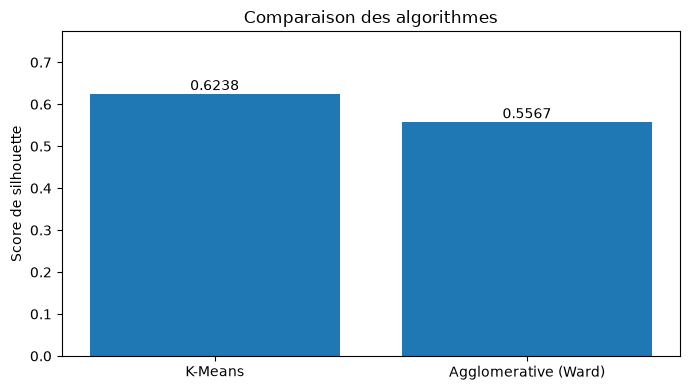

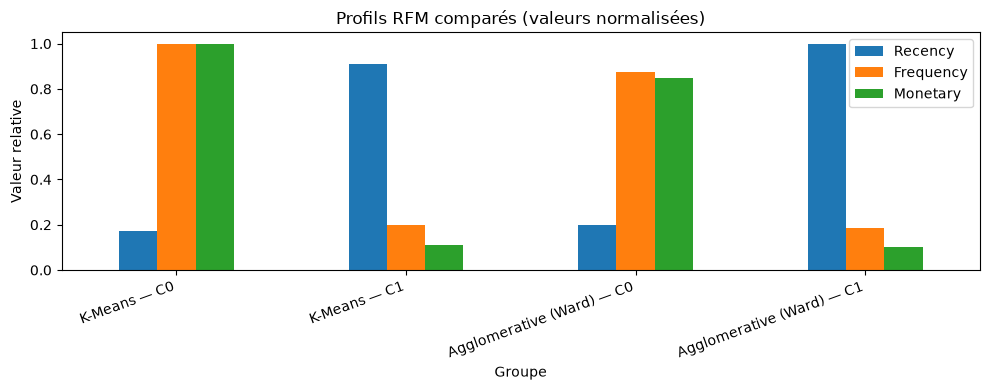

Algorithme retenu : K-Means (silhouette = 0.6238)
Le score guide le choix ; les profils RFM servent à vérifier l'interprétation métier.
+-------+-------------+---------------+-----------------+----------------+
|Cluster|NombreClients|Recency_Moyenne|Frequency_Moyenne|Monetary_Moyenne|
+-------+-------------+---------------+-----------------+----------------+
|0      |1654         |25.39          |8.49             |4566.18         |
|1      |2684         |133.15         |1.68             |497.3           |
+-------+-------------+---------------+-----------------+----------------+



In [24]:
scores = comparison_results.sort_values("Silhouette", ascending=False)

plt.figure(figsize=(7, 4))
bars = plt.bar(scores["Algorithme"], scores["Silhouette"])
plt.ylabel("Score de silhouette")
plt.title("Comparaison des algorithmes")
plt.ylim(0, min(1, scores["Silhouette"].max() + 0.15))
for bar, value in zip(bars, scores["Silhouette"]):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.4f}", ha="center")
plt.tight_layout()
plt.show()

profile_plot = profiles_comparison.copy()
for column in ["Recency", "Frequency", "Monetary"]:
    maximum = profile_plot[column].max()
    profile_plot[column] = profile_plot[column] / maximum if maximum else 0

profile_plot["Groupe"] = profile_plot.apply(
    lambda row: f"{row['Algorithme']} — C{row['Cluster']}", axis=1
)
profile_plot.set_index("Groupe")[["Recency", "Frequency", "Monetary"]].plot(
    kind="bar", figsize=(10, 4)
)
plt.title("Profils RFM comparés (valeurs normalisées)")
plt.ylabel("Valeur relative")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best = comparison_results.loc[comparison_results["Silhouette"].idxmax()]
selected_algorithm = best["Algorithme"]
selected_column = "KMeansCluster" if selected_algorithm == "K-Means" else "AgglomerativeCluster"

selected_pd = comparison_pd[
    ["CustomerID", "Recency", "Frequency", "Monetary", selected_column]
].rename(columns={selected_column: "Cluster"})

customer_segments = spark.createDataFrame(selected_pd)
customer_segments = customer_segments.withColumn("Cluster", F.col("Cluster").cast("int"))

final_profiles = (
    customer_segments.groupBy("Cluster")
    .agg(
        F.countDistinct("CustomerID").alias("NombreClients"),
        F.round(F.avg("Recency"), 2).alias("Recency_Moyenne"),
        F.round(F.avg("Frequency"), 2).alias("Frequency_Moyenne"),
        F.round(F.avg("Monetary"), 2).alias("Monetary_Moyenne")
    )
    .orderBy("Cluster")
)

print(f"Algorithme retenu : {selected_algorithm} (silhouette = {best['Silhouette']:.4f})")
print("Le score guide le choix ; les profils RFM servent à vérifier l'interprétation métier.")
final_profiles.show(truncate=False)


## 10. Visualisations de la segmentation retenue

Les graphiques ci-dessous utilisent les labels de l’algorithme sélectionné dans la comparaison précédente.

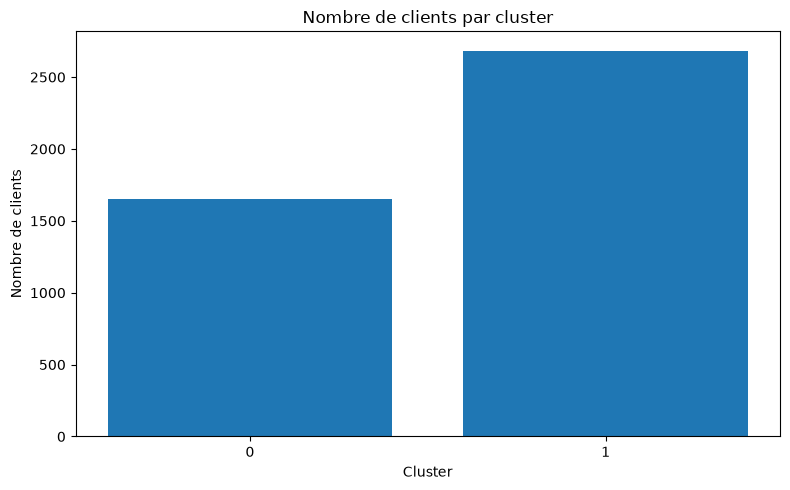

In [25]:
import matplotlib.pyplot as plt

cluster_counts = (
    customer_segments
    .groupBy("Cluster")
    .count()
    .orderBy("Cluster")
    .collect()
)

clusters = [row["Cluster"] for row in cluster_counts]
counts = [row["count"] for row in cluster_counts]

plt.figure(figsize=(8, 5))

plt.bar(
    [str(c) for c in clusters],
    counts
)

plt.title("Nombre de clients par cluster")
plt.xlabel("Cluster")
plt.ylabel("Nombre de clients")

plt.tight_layout()
plt.show()

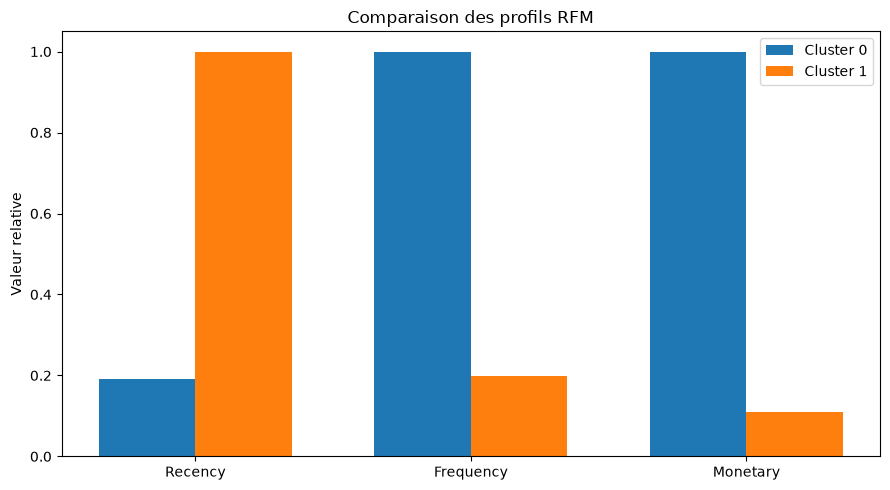

In [26]:
profile_pd = (
    final_profiles
    .select(
        "Cluster",
        "Recency_Moyenne",
        "Frequency_Moyenne",
        "Monetary_Moyenne"
    )
    .orderBy("Cluster")
    .toPandas()
)

for col in [
    "Recency_Moyenne",
    "Frequency_Moyenne",
    "Monetary_Moyenne"
]:
    profile_pd[col] = (
        profile_pd[col] / profile_pd[col].max()
    )

plt.figure(figsize=(9, 5))

x = range(3)
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    profile_pd.iloc[0, 1:],
    width,
    label="Cluster 0"
)

plt.bar(
    [i + width/2 for i in x],
    profile_pd.iloc[1, 1:],
    width,
    label="Cluster 1"
)

plt.xticks(
    x,
    ["Recency", "Frequency", "Monetary"]
)

plt.ylabel("Valeur relative")
plt.title("Comparaison des profils RFM")
plt.legend()

plt.tight_layout()
plt.show()

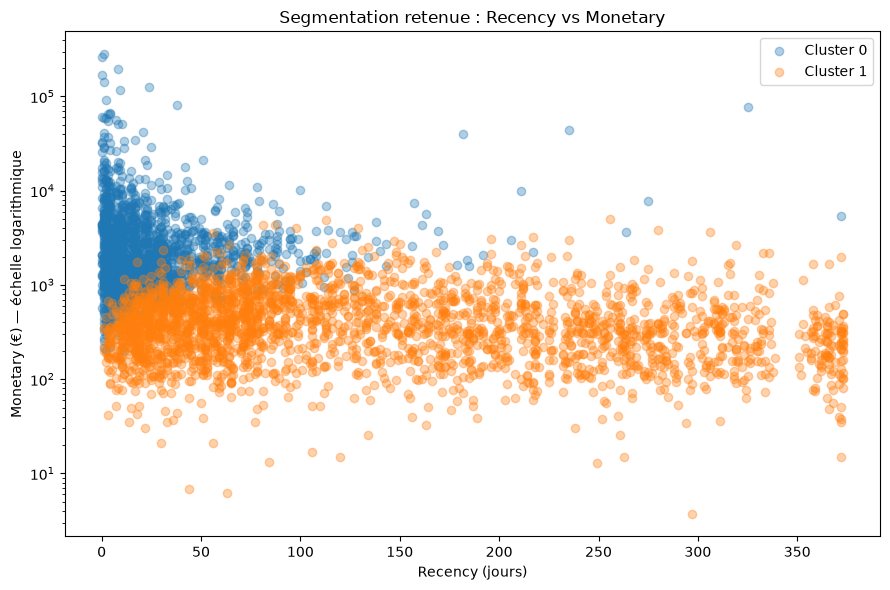

In [27]:
scatter_pd = (
    customer_segments
    .select(
        "Recency",
        "Monetary",
        "Cluster"
    )
    .toPandas()
)

plt.figure(figsize=(9, 6))

for cluster in sorted(scatter_pd["Cluster"].unique()):

    data = scatter_pd[
        scatter_pd["Cluster"] == cluster
    ]

    plt.scatter(
        data["Recency"],
        data["Monetary"],
        alpha=0.35,
        label=f"Cluster {cluster}"
    )

plt.yscale("log")

plt.xlabel("Recency (jours)")
plt.ylabel("Monetary (€) — échelle logarithmique")
plt.title("Segmentation retenue : Recency vs Monetary")
plt.legend()

plt.tight_layout()
plt.show()

## 11. Sauvegarde de la segmentation retenue

In [28]:
print("Saving selected customer segmentation")

output_path = "/home/jovyan/work/data/processed/customer_segments"

customer_segments.write \
    .mode("overwrite") \
    .parquet(output_path)

print(f"Selected segmentation saved to: {output_path}")

Saving selected customer segmentation
Selected segmentation saved to: /home/jovyan/work/data/processed/customer_segments
